# QoE contínuo × QoE pós-vídeo

## 1. Configuração

In [35]:
import torch
import torch.nn as nn

import os
import re
import glob

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor

DATA_ROOT = "."

QOEC_DIR = os.path.join(DATA_ROOT, "QoE_Annotation_Data", "Continuous_QoE_Score")
QOEP_DIR = os.path.join(DATA_ROOT, "QoE_Annotation_Data", "Post_Video_QoE_Score")

def extract_pv(filename):
    m = re.search(r'[Pp](\d+)_[Vv](\d+)', os.path.basename(filename))
    if not m:
        raise ValueError(f"Não consegui extrair P/V de: {filename}")
    return int(m.group(1)), int(m.group(2))

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. QoE contínuo

In [36]:
dfs = []
for arquivo in glob.glob(os.path.join(QOEC_DIR, "RCQoE_*.txt")):
    participante, video = extract_pv(arquivo)
    df = pd.read_csv(arquivo, sep=';', usecols=[0, 1, 2])
    df.columns = ['ID', 'TimeStamp', 'RCQoE']
    df['Participante'] = participante
    df['Video'] = video
    dfs.append(df)

qoec = pd.concat(dfs, ignore_index=True).sort_values(['Participante', 'Video', 'ID'])
qoec = qoec.reset_index(drop=True)

print(qoec.shape)
qoec.head()

(149185, 5)


,ID,TimeStamp,RCQoE,Participante,Video
0,0,1.433739e+10,0.0,1,1
1,1,1.433749e+10,0.0,1,1
2,2,1.433759e+10,0.0,1,1
3,3,1.433769e+10,0.0,1,1
4,4,1.433779e+10,0.0,1,1


In [37]:
qoec['RCQoE'].describe()

count    149185.000000
mean          0.400326
std           0.296072
min           0.000000
25%           0.071447
50%           0.434678
75%           0.639027
max           0.999671
Name: RCQoE, dtype: float64

Podemos observar que o valor mínimo do Score de QoE contínuo é zero, sendo que o esperado seria -1. 

In [38]:
# qual é a média de entradas por participante e por vídeo?
media_entradas = qoec.groupby(['Participante', 'Video']).size().mean()
print(f"Média de entradas por participante e vídeo: {media_entradas:.2f}")

Média de entradas por participante e vídeo: 116.55


## 3. QoE pós-vídeo

In [39]:
registros = []
for arquivo in glob.glob(os.path.join(QOEP_DIR, "PostQuestion_*.txt")):
    participante, video = extract_pv(arquivo)
    linhas = open(arquivo).read().splitlines()
    registros.append({
        'Participante': participante,
        'Video': video,
        'MOS': int(linhas[1].split(';')[2]),
    })

qoep = pd.DataFrame(registros).sort_values(['Participante', 'Video']).reset_index(drop=True)

print(qoep.shape)
qoep['MOS'].value_counts().sort_index()

(1280, 3)


MOS
1    100
2    238
3    473
4    347
5    122
Name: count, dtype: int64

([<matplotlib.axis.XTick at 0x20dafb431d0>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5')])

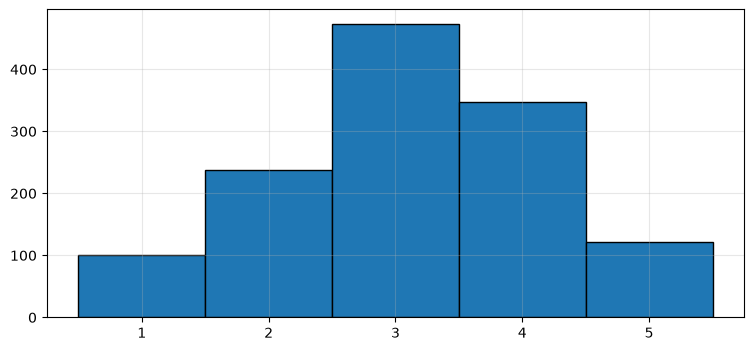

In [40]:
# histograma do MOS
plt.hist(qoep['MOS'], bins=np.arange(1, 7) - 0.5, edgecolor='black')
plt.xticks(range(1, 6))

In [41]:
# qual é a média de MOS por participante e por vídeo?
media_mos = qoep.groupby(['Participante', 'Video'])['MOS'].mean().mean()
print(f"Média de MOS por participante e vídeo: {media_mos:.2f}")

Média de MOS por participante e vídeo: 3.12


In [42]:
# MOS médio por vídeo
mos_medio_video = (
    qoep.groupby('Video')['MOS']
        .agg(['mean', 'std', 'count'])
        .rename(columns={'mean': 'MOS_medio'})
        .round(2)
)

display(mos_medio_video)

,MOS_medio,std,count
Video,,,
1,4.06,0.72,32
2,3.94,0.88,32
3,3.16,0.88,32
4,1.38,0.61,32
5,2.84,0.99,32
6,2.69,0.69,32
7,2.72,0.85,32
8,2.69,0.59,32
9,4.00,0.92,32


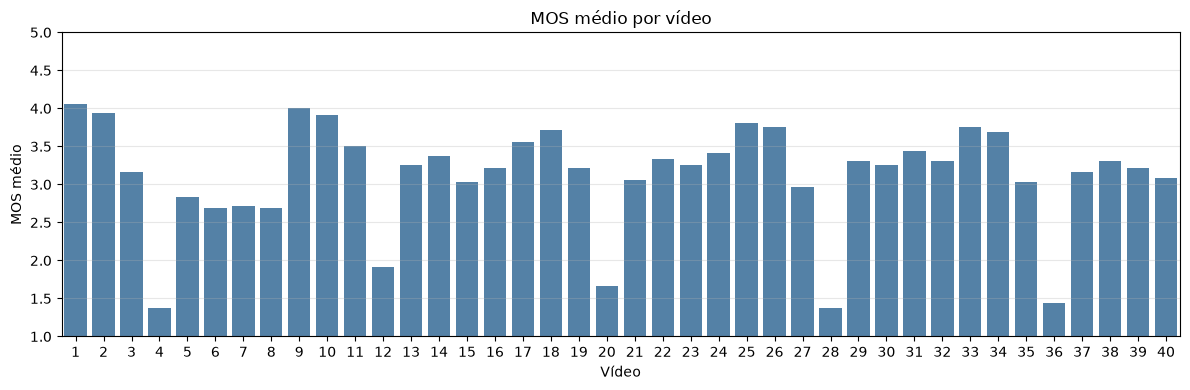

In [43]:
plt.figure(figsize=(12, 4))

sns.barplot(
    data=mos_medio_video.reset_index(),
    x='Video',
    y='MOS_medio',
    color='steelblue',
    errorbar=None
)

plt.xlabel('Vídeo')
plt.ylabel('MOS médio')
plt.ylim(1, 5)
plt.title('MOS médio por vídeo')
plt.tight_layout()
plt.show()

Segundo a documentação, o *Video ID* identifica a condição, não a ordem em que o participante assistiu

## 4. Integridade das séries

sessões: 1280
comprimento min/mediana/max: 78 117.0 119
amostras exatamente zero: 21.0%
zeros iniciais (mediana): 22.0
séries zeradas: 47


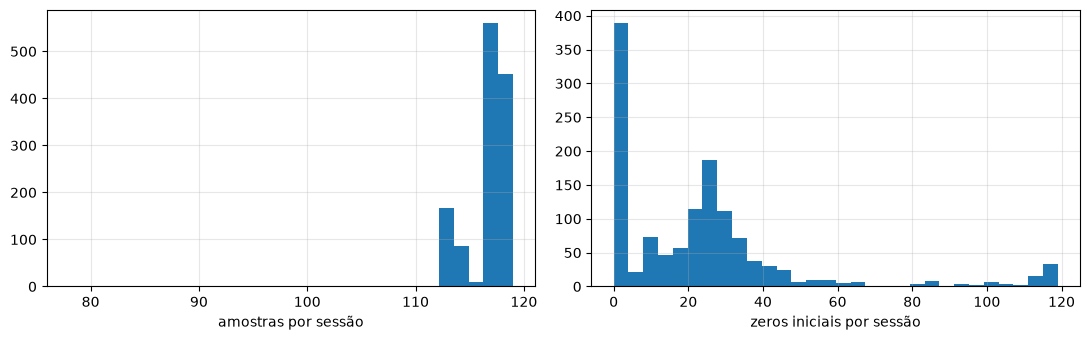

In [44]:
comprimentos = qoec.groupby(['Participante', 'Video'])['ID'].size()
zeros_iniciais = qoec.groupby(['Participante', 'Video'])['RCQoE'].apply(
    lambda s: int(np.argmax(s.values != 0)) if (s.values != 0).any() else len(s)
)
serie_nula = qoec.groupby(['Participante', 'Video'])['RCQoE'].std() == 0

print("sessões:", len(comprimentos))
print("comprimento min/mediana/max:", comprimentos.min(), comprimentos.median(), comprimentos.max())
print("amostras exatamente zero: %.1f%%" % (100 * (qoec['RCQoE'] == 0).mean()))
print("zeros iniciais (mediana):", zeros_iniciais.median())
print("séries zeradas:", int(serie_nula.sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(comprimentos, bins=30)
ax[0].set_xlabel("amostras por sessão")
ax[1].hist(zeros_iniciais, bins=30)
ax[1].set_xlabel("zeros iniciais por sessão")
plt.tight_layout()
plt.show()

Como cada vídeo tem 30s e no QoE contínuo a frequência da resposta é 10 Hz, então deveríamos ter em torno de 300 amostras no vídeo inteiro. Porem a média de amostras por vídeo na maioria das sessões é de 117.

- Uma hipótese pode ser que os participantes tinham um delay e então valores repetidos em sequência foram excluídos. Não sei, preciso olhar o artigo

47 sessões são inteiramente constantes (quase todas zeradas). São participantes que não mexeram no touchpad naquele vídeo e ainda assim deram MOS 4 ou 5

In [ ]:
# quem são os participantes que mais zeraram a série? TODO AVALIAR DADOS PESSOAIS DOS 5 PRIMEIROS PARTICIPANTES DA TABELA ABAIXO
participantes_mais_zeros = qoec[qoec['RCQoE'] == 0].groupby('Participante').size().sort_values(ascending=False)
print(participantes_mais_zeros)

Participante
5     3495
1     2757
14    2158
10    1889
17    1536
9     1436
20    1347
12    1311
2     1292
6     1254
11    1188
19    1131
27    1088
25    1042
8     1030
15     937
7      838
29     786
31     749
30     667
28     663
3      512
32     511
26     490
13     409
18     334
23     153
22     132
16      90
4       48
24       7
dtype: int64


In [46]:
# quais vídeos tiveram mais zeros?
videos_mais_zeros = qoec[qoec['RCQoE'] == 0].groupby('Video').size().sort_values(ascending=False)
print(videos_mais_zeros)

Video
25    1044
10     946
1      930
33     925
18     922
39     901
7      901
4      888
23     880
22     860
17     857
32     835
12     815
13     813
24     802
20     798
11     798
14     793
29     792
3      788
38     785
28     768
8      764
34     742
36     738
2      736
16     731
6      728
30     722
40     715
5      709
31     701
19     697
9      676
35     671
26     640
37     636
27     633
21     607
15     593
dtype: int64


## 6. Agregados por sessão

In [48]:
sessoes = chaves.copy()
sessoes['media'] = curvas.mean(axis=1)
sessoes['mediana'] = np.median(curvas, axis=1)
sessoes['desvio'] = curvas.std(axis=1)
sessoes['minimo'] = curvas.min(axis=1)
sessoes['maximo'] = curvas.max(axis=1)
sessoes['final'] = curvas[:, -1] # o último valor da série reamostrada, ou seja, a nota contínua que o participante estava marcando no instante final do vídeo.
sessoes['final_10'] = curvas[:, -10:].mean(axis=1) # a média dos últimos 10 pontos (últimos 10% do vídeo) - o final é um único ponto e, portanto, sensível a ruído, então foi adicionado o final_10 pra ser um final suavizado.
sessoes['frac_zeros'] = (curvas == 0).mean(axis=1)

base = sessoes.merge(qoep, on=['Participante', 'Video'])

print(base.shape)
base.head()

(1280, 11)


,Participante,Video,media,mediana,desvio,minimo,maximo,final,final_10,frac_zeros,MOS
0,1,1,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.00,5
1,1,2,0.493446,0.652483,0.270594,0.0,0.658464,0.656531,0.655716,0.23,5
2,1,3,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.00,4
3,1,4,0.101917,0.073712,0.113958,0.0,0.374535,0.168505,0.167217,0.50,1
4,1,5,0.372172,0.272914,0.229100,0.0,0.902727,0.272590,0.256409,0.06,2


## 7. Distribuições

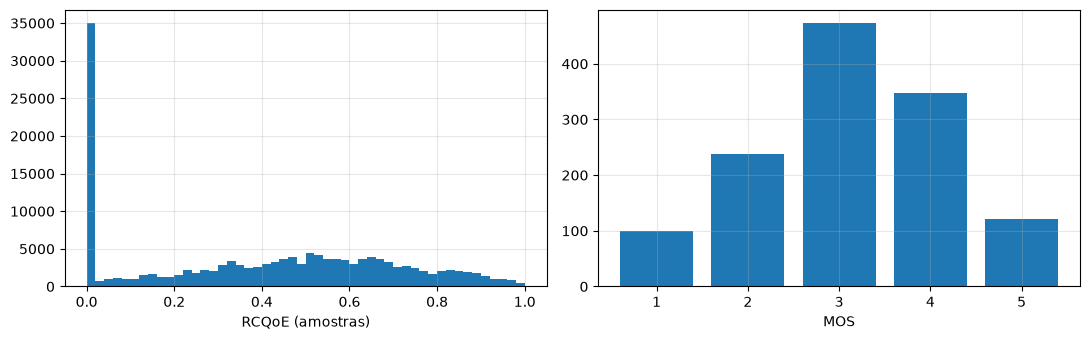

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(qoec['RCQoE'], bins=50)
ax[0].set_xlabel("RCQoE (amostras)")
ax[1].bar(base['MOS'].value_counts().sort_index().index,
          base['MOS'].value_counts().sort_index().values)
ax[1].set_xlabel("MOS")
plt.tight_layout()
plt.show()

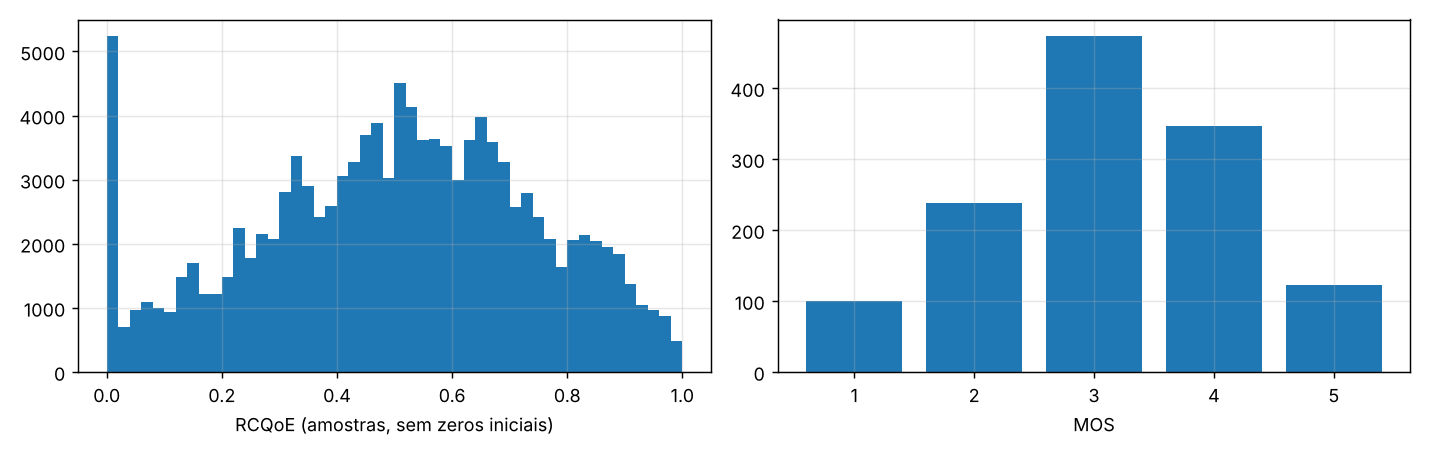

Vemos que para o RCQoE se concentra em maioria no zero. Isso seria equivalente a um MOS = 1, coisa que não vemos no gráfico de MOS. Se desconsiderássemos os zeros, vemos que a distribuição se assemelha mais ao QoE pós vídeo. 

## 8. Curva média de QoEC por nível de MOS

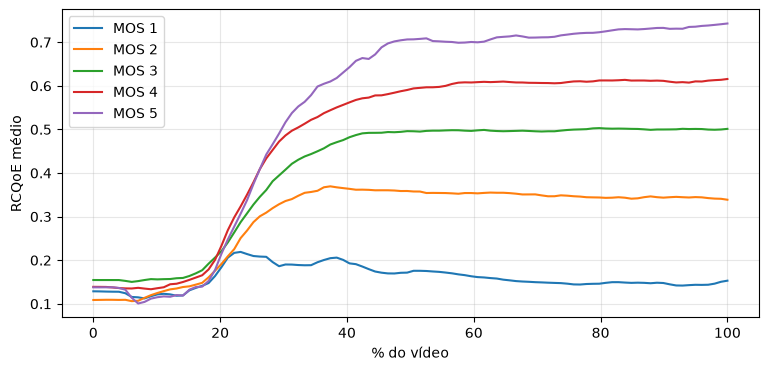

In [51]:
plt.figure()
for mos in sorted(base['MOS'].unique()):
    plt.plot(np.linspace(0, 100, T), curvas[(base['MOS'] == mos).values].mean(axis=0), label=f"MOS {mos}")
plt.xlabel("% do vídeo")
plt.ylabel("RCQoE médio")
plt.legend()
plt.show()

Mesmo com o problema de escala na classificação do RCQoE, vemos que a média do RCQoE atinge um platô próximo à metade do vídeo. E de fato, quanto menor o MOS, menor a média do RCQoE. 

In [52]:
# dividir valores possíveis de RCQoE em partes iguais e ver a qual MOS ele seria relacionado? 

## 9. Agregados de QoEC contra MOS

In [53]:
metricas = ['media', 'mediana', 'desvio', 'minimo', 'maximo', 'final', 'final_10', 'frac_zeros']

correl = pd.DataFrame({
    'pearson': [pearsonr(base[m], base['MOS'])[0] for m in metricas],
    'spearman': [spearmanr(base[m], base['MOS'])[0] for m in metricas],
}, index=metricas).round(3)

correl.sort_values('spearman', ascending=False)

,pearson,spearman
final,0.609,0.614
final_10,0.603,0.606
mediana,0.536,0.545
media,0.509,0.514
maximo,0.440,0.487
desvio,0.375,0.387
minimo,0.061,0.007
frac_zeros,-0.019,-0.011


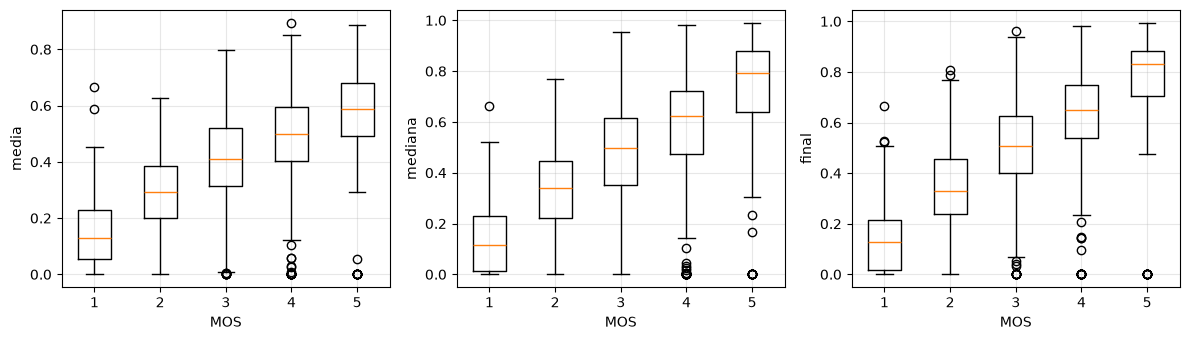

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for eixo, m in zip(ax, ['media', 'mediana', 'final']):
    eixo.boxplot([base.loc[base['MOS'] == k, m] for k in sorted(base['MOS'].unique())],
                 tick_labels=sorted(base['MOS'].unique()))
    eixo.set_xlabel("MOS")
    eixo.set_ylabel(m)
plt.tight_layout()
plt.show()

Vemos pelos boxplots que os valores de média, mediana e valor final do RCQoE está alinhado com o valor MOS dado pós vídeo, com algumas excessões 